## Dataset 
Given data set in `digits-dataset.mat` contains $n = 5000$ training examples of handwritten digits. Each training example is a vector in $\mathbb{R}^d$ where $d=400$, resulting from a 20 pixel by 20 pixel grayscale image of the digit. In order words, each pixel is represented by a floating point number indicating the grayscale intensity at that location; the 20 by 20 grid of pixels was "*unrolled*" (i.e. flattened) into a 400-dimensional vector. So, each of these training examples becomes a single row in our data matrix $X$. This gives us a $5000 \times 400$ matrix $X \in \mathbb{R}^{5000 \times 400}$ where every row is a training example for a handwritten digit image.

The second part of the training set is a vector $y$ of dimension 5000, that contains labels for the training set.

Input shape X = (5000, 400)
Output shape y = (5000,)
Unique labels y =  [0 1 2 3 4 5 6 7 8 9]
Plotting 100 digits: 


C:\Users\sahbi\AppData\Local\Temp\ipykernel_25764\3271848871.py:33: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


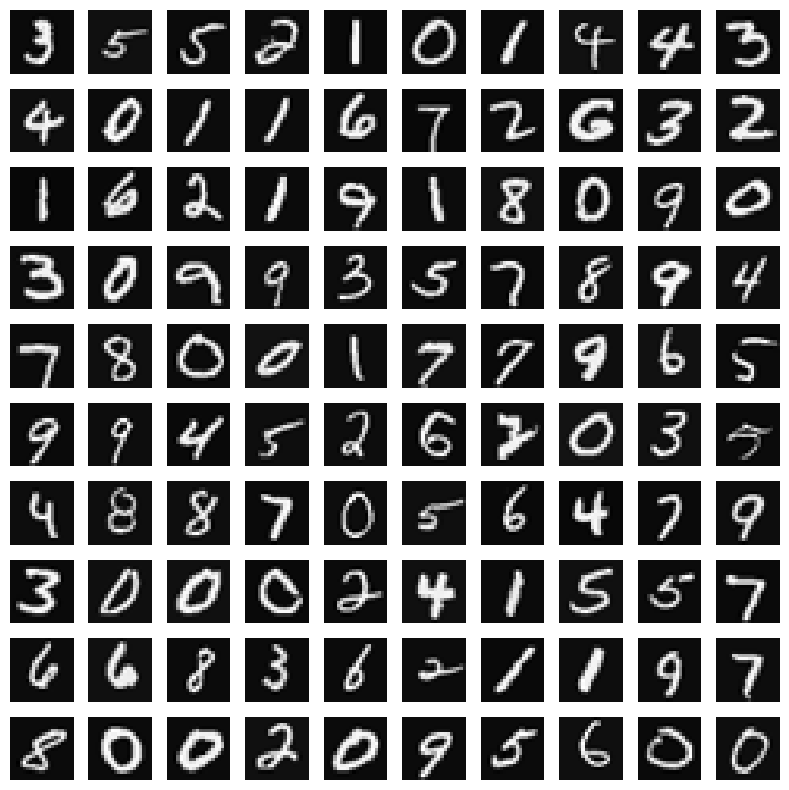

In [103]:
# Load and Visualize 
from scipy.io import loadmat
import matplotlib.pyplot as plt 
import numpy as np


filepath = "datasets/digits-dataset.mat"

mat_data = loadmat(filepath)
X  = mat_data["X"].astype(np.float32)    # X
y  = mat_data["y"].flatten()  # Y 

# Data shape 
print("Input shape X =",X.shape)
print("Output shape y =", y.shape)
print("Unique labels y = ", np.unique(y))

#Visulaize n digits 

def visualize_100_digits(X): 
    ids = np.random.choice(len(X), 100, replace= False)
    images = X[ids].reshape(100, 20, 20)

    print("Plotting 100 digits: ")
    fig, axes = plt.subplots(10, 10,figsize=(8, 8))

    for i in range(10):
        for j in range(10):
            img = images[i*10+j].T
            axes[i][j].imshow( img, cmap='gray' )
            axes[i][j].axis("off")
    plt.tight_layout()
    fig.show()
visualize_100_digits(X)


X_2d shape: (5000, 2)
Explained variance per components =   [0.11060633 0.07975677]
Total kept =  0.1903631
((0.12156862745098039, 0.4666666666666667, 0.7058823529411765), (1.0, 0.4980392156862745, 0.054901960784313725), (0.17254901960784313, 0.6274509803921569, 0.17254901960784313), (0.8392156862745098, 0.15294117647058825, 0.1568627450980392), (0.5803921568627451, 0.403921568627451, 0.7411764705882353), (0.5490196078431373, 0.33725490196078434, 0.29411764705882354), (0.8901960784313725, 0.4666666666666667, 0.7607843137254902), (0.4980392156862745, 0.4980392156862745, 0.4980392156862745), (0.7372549019607844, 0.7411764705882353, 0.13333333333333333), (0.09019607843137255, 0.7450980392156863, 0.8117647058823529))


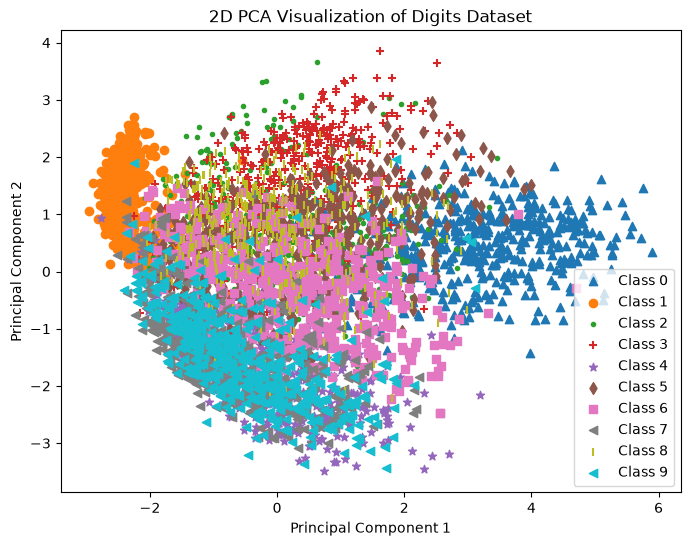

In [104]:
# Visualize using PCA 
from sklearn.decomposition import PCA

pca = PCA(n_components = 2) # Here only for visualization
X_pca = pca.fit_transform(X) # finds two directions in which the 400 pixel values vary the most 
                            # (5000, 2)

print("X_2d shape:", X_pca.shape)
print("Explained variance per components =  ", pca.explained_variance_ratio_)
print("Total kept = ", pca.explained_variance_ratio_.sum())


# Visualize 
fig, ax = plt.subplots(figsize=(8, 6))
markers = ["^", "o", ".", "+", "*", "d", "s", "<", "|", "<"]
colors = plt.cm.tab10.colors # gets 10 colors from the tab10 colormap
classes = np.unique(y) # finds unique classes in dataset (0-9)
print(colors)

for i, cls in enumerate(classes):
    mask = (y == cls) # get indcies matching class
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], marker=markers[i], color=colors[i], label=f"Class {cls}")

ax.set_title("2D PCA Visualization of Digits Dataset")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.legend()
plt.show()

# Model Train Choise :
1. Out of the training models (MLP, CNN, Tiny ResNet ) : MLP to be used as a baseling , followed by CNN 
2. Assumptions: 
    - For air drawn pattern recognization with the 2d training data set can be tricky as model will not be introduced to it 
    - Thus, MLP need mrore neuron and even more data to covers the maximum edges while CNN has a small window and shared the pattern it learnt(inductive bias), making it requires fewer parameters, may be accurate in detecting unseen shifted data(shifted digits)
3. Approached: 
    - Train MLP and CNN 
    - Compare their computational power, accuracy,  space constraint,  time of execution and first layer weights 
    - Quatize one model based on their comaprision 
    - Inference to esp32
    - Test with raw stroke 
    - Deploy with esp32 camera 


X: (5000, 400) y: (5000,) labels: [0 1 2 3 4 5 6 7 8 9]
train data length = 3612
val data length   = 638
test data length  = 750


Model: "sequential_40"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_72 (Dense)                │ (None, 128)            │        51,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_42 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_73 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,618 (205.54 KB)

 Trainable params: 52,618 (205.54 KB)

 Non-trainable params: 0 (0.00 B)


 =========== MODEL TRAINING ===================
Epoch 1/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6741 - loss: 1.1922 - val_accuracy: 0.8636 - val_loss: 0.5857
Epoch 2/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8541 - loss: 0.5160 - val_accuracy: 0.8918 - val_loss: 0.4116
Epoch 3/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8901 - loss: 0.3916 - val_accuracy: 0.9075 - val_loss: 0.3556
Epoch 4/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9103 - loss: 0.3318 - val_accuracy: 0.9154 - val_loss: 0.3146
Epoch 5/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9175 - loss: 0.2927 - val_accuracy: 0.9154 - val_loss: 0.2974
Epoch 6/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9269 - loss: 0.2574 - val_accuracy: 0.9248 - val_loss: 0.2798
Epoch 7/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9380 - loss: 0.2278 - val_accuracy: 0.9248 - val_loss: 0.2642
Epoch 8/100
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/

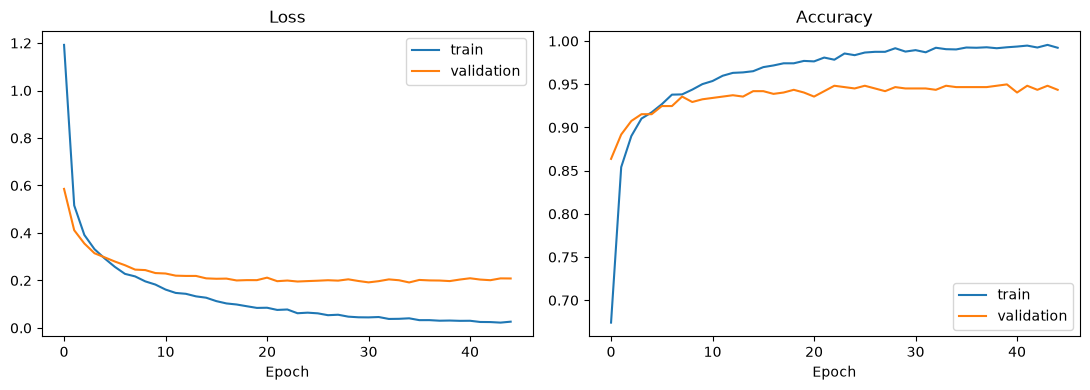

In [105]:
# MLP Baseline trainig 
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

np.random.seed(42)
tf.random.set_seed(42)

X = np.clip(X, 0.0, 1.0) # making sure pixel is in between 0 to 1.0 

print("X:", X.shape, "y:", y.shape, "labels:", np.unique(y))


# Test : for final accuracy test 
# validate: check after every epoch, to decide when to stop

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=42)

print("train data length =", len(X_train))
print("val data length   =",  len(X_val))
print("test data length  =", len(X_test))

model= tf.keras.Sequential([
    tf.keras.Input(shape=(400,)),
    tf.keras.layers.Dense(128, activation="relu"), # hidden layer 1 
    tf.keras.layers.Dropout(0.3),   # to stop relying on specific neurons: reduce overfitting 
    tf.keras.layers.Dense(10, activation="softmax"),
])


model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",   # labels are plain integers 0..9
    metrics=["accuracy"],
)
model.summary()  


# MLP Model train 
print ("\n =========== MODEL TRAINING ===================")
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
)

#  Learning plot 
print ("\n =========== LEARNING PLOT ===================")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(history.history["loss"], label="train")
ax1.plot(history.history["val_loss"], label="validation")
ax1.set_title("Loss"); ax1.set_xlabel("Epoch"); ax1.legend()

ax2.plot(history.history["accuracy"], label="train")
ax2.plot(history.history["val_accuracy"], label="validation")
ax2.set_title("Accuracy"); ax2.set_xlabel("Epoch"); ax2.legend()
plt.tight_layout(); plt.savefig("mlp_curves.png", dpi=150); plt.show()

In [106]:
# Model test evaluation 
test_loss, test_acc =  model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}  ({int(round(test_acc * len(y_test)))}/{len(y_test)} correct)")
model.save("mlp_digits.keras")

Test loss:     0.2297
Test accuracy: 0.9453  (709/750 correct)


## Analysis  
- Sign of overfitting
- Validation accuracy stays bet 93 to 95%
- training accuract keeps on raising - sign of memorizing, 
- gap between validation and training error -> increases 
## Step Analyzed
- little improvement between only 1 hidden layers and two hidden layers.
- Choosing only one hidden layer 


In [107]:
# Evaluate CNN model

np.random.seed(42)
tf.random.set_seed(42)

# Convert to real 2d images 
   # order="F" reads the numbers column by column, the way MATLAB stored them. 
   # Skipping it, every digit is transposed (mirrored along the diagonal). 
   # The model would still train, but the camera canvas you build on the ESP32 later must have the same orientation, so keep it upright from the start.
X_img = X.reshape(-1, 20, 20, order='F')    
X_img = X_img[..., np.newaxis]   # add channel axis : for grey picture = 1 :(5000, 20, 20) becomes (5000, 20, 20, 1)

# Data Split 
X_train, X_test, y_train, y_test = train_test_split(X_img, y, test_size=0.15, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.15, stratify=y_train, random_state=42)

print("train data length =", len(X_train))
print("val data length   =",  len(X_val))
print("test data length  =", len(X_test))

# Data Augmentation : let model know about rotational and transaltional data type 
    # Each time a training images is used, it's randomly rotated, shifted and zoomed a little 
    # fill_mode="constant" fills the gaps created by moving or rotating with 0, which is black and matches the background.
augment = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.04, fill_mode="constant"),         # about ±15°
    tf.keras.layers.RandomTranslation(0.1, 0.1, fill_mode="constant"),  # about ±2 pixels
    tf.keras.layers.RandomZoom(0.1, fill_mode="constant"),              # ±10% size
])

# Input pipeline 
train_ds = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
            .shuffle(len(X_train))
            .batch(64)  # a group of images the model looks at before it update its weights once
            .map(lambda x, t: (augment(x, training=True), t), #  x = batch images , t = target labels
                 num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE))    # To prepapre next batch while current one is training : AUTOTUNE : Tensorflow decide how many batched to keeo ready 


# Model     
cnn = tf.keras.Sequential([
    tf.keras.Input(shape=(20, 20, 1)),
    tf.keras.layers.Conv2D(8, 3, padding="same", activation="relu"),   # -> (20, 20, 8)
    tf.keras.layers.MaxPooling2D(),                                    # -> (10, 10, 8)
    tf.keras.layers.Conv2D(16, 3, padding="same", activation="relu"),  # -> (10, 10, 16)
    tf.keras.layers.MaxPooling2D(),                                    # -> (5, 5, 16)
    tf.keras.layers.Flatten(),                                         # -> (400,)
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(32, activation="relu"),                      # -> (32,)
    tf.keras.layers.Dense(10, activation="softmax"),                   # -> (10,)
])


# Compile and summary 
cnn.compile(optimizer="adam",
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])
cnn.summary()

# Train (early stop and history)
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True)
history = cnn.fit(train_ds, validation_data=(X_val, y_val),
                  epochs=100, callbacks=[early_stop])

train data length = 3612
val data length   = 638
test data length  = 750


Model: "sequential_42"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_18 (Conv2D)              │ (None, 20, 20, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 10, 10, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 10, 10, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_43 (Dropout)            │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_74 (Dense)                │ (None, 32)             │        12,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_75 (Dense)                │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,410 (56.29 KB)

 Trainable params: 14,410 (56.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100


d:\Projects\Embeeded AI\Air-Drawn Digit Recognition with TinyML\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.1985 - loss: 2.2216 - val_accuracy: 0.6129 - val_loss: 1.8037
Epoch 2/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4837 - loss: 1.5946 - val_accuracy: 0.7759 - val_loss: 0.8149
Epoch 3/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6063 - loss: 1.1889 - val_accuracy: 0.8448 - val_loss: 0.5820
Epoch 4/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6791 - loss: 0.9811 - val_accuracy: 0.8417 - val_loss: 0.5301
Epoch 5/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7292 - loss: 0.8197 - val_accuracy: 0.8918 - val_loss: 0.3976
Epoch 6/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7663 - loss: 0.7132 - val_accuracy: 0.8966 - val_loss: 0.3684
Epoch 7/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7841 - loss: 0.6579 - val_accuracy: 0.9169 - val_loss: 0.3053
Epoch 8/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8228 - loss: 0.5706 - val_accuracy: 0.9044 - val_loss: 0.3

In [108]:
# test and save 
test_loss, test_acc = cnn.evaluate(X_test, y_test, verbose=0)
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}  ({int(round(test_acc * len(y_test)))}/{len(y_test)} correct)")
cnn.save("cnn_digits.keras")

Test loss:     0.0933
Test accuracy: 0.9693  (727/750 correct)


## Model Comparision (MLP VS CNN)


### Helpers 

In [109]:
import os 
from sklearn.metrics import accuracy_score


def get_file_size_in_kb(file_path):
    size = os.path.getsize(file_path)
    size_in_kb = str(round(size / 1024, 3))
    return size_in_kb

    

In [110]:
mlp_model_path = "mlp_digits.keras"
cnn_model_path = "cnn_digits.keras"

mlp_original_size = get_file_size_in_kb(mlp_model_path)
cnn_original_size = get_file_size_in_kb(cnn_model_path)

print(f"MLP ORIGINAL SIZE = {mlp_original_size} KB ")
print(f"CNN ORIGINAL SIZE = {cnn_original_size} KB ")

cnn_original = tf.keras.models.load_model(cnn_model_path) 
print("Original Input Shape: ", cnn_original.input_shape)
print("Original Output Shape: ", cnn_original.output_shape)
print("Input dtype :", cnn_original.inputs[0].dtype)  
print("Output dtype:", cnn_original.outputs[0].dtype) 
print("Input name  :", cnn_original.inputs[0].name)

MLP ORIGINAL SIZE = 639.316 KB 
CNN ORIGINAL SIZE = 207.725 KB 
Original Input Shape:  (None, 20, 20, 1)
Original Output Shape:  (None, 10)
Input dtype : float32
Output dtype: float32
Input name  : input_layer_41


In [111]:
# ================== Converting  16 =========================


# Initialize the file 
CNN_LITE_MODEL_16 = "cnn_lite_16.tflite"

# call converter 
cnn_lite_converter = tf.lite.TFLiteConverter.from_keras_model(cnn_original)

# perform optimization(Quantization 16 bit)
cnn_lite_converter.optimizations  = [tf.lite.Optimize.DEFAULT]
cnn_lite_converter.target_spec.supported_types = [tf.float16]

# Convert 
cnn_lite_model_16 = cnn_lite_converter.convert()

open(CNN_LITE_MODEL_16, "wb").write(cnn_lite_model_16)

# check converted size 
cnn_lite_16_size = get_file_size_in_kb(CNN_LITE_MODEL_16)
print(f"CNN LITE 16 SIZE: {cnn_lite_16_size}, KB")
compress_ratio = float(cnn_lite_16_size) / float(cnn_original_size)
print(f"Size compressed by : {compress_ratio}")

# Check Accuracy 
    # Set interpreter 
interpreter = tf.lite.Interpreter(model_content=cnn_lite_model_16)
    
    # check input and output details (shape and size ) 
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()
print("Input Shape 16:", input_details[0]['shape'])
print("Input Type 16 :", input_details[0]['dtype'])
print("Output Shape 16 :", output_details[0]['shape'])
print("Output Type 16 :", output_details[0]['dtype'])

INFO:tensorflow:Assets written to: C:\Users\sahbi\AppData\Local\Temp\tmp4f7lf0y5\assets


INFO:tensorflow:Assets written to: C:\Users\sahbi\AppData\Local\Temp\tmp4f7lf0y5\assets


Saved artifact at 'C:\Users\sahbi\AppData\Local\Temp\tmp4f7lf0y5'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 20, 20, 1), dtype=tf.float32, name='input_layer_41')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  1899282471760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1899408242448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1899408230160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1899408237456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1899408236304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1899408230736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1899408230928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1899408234000: TensorSpec(shape=(), dtype=tf.resource, name=None)
CNN LITE 16 SIZE: 33.98, KB
Size compressed by : 0.16358165844265254
Input Shape 16: [ 1 20 20  1]
Input Type 16 : <class 'numpy.float32'>
Out

d:\Projects\Embeeded AI\Air-Drawn Digit Recognition with TinyML\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [112]:
    # Resize tensor shape 
interpreter.resize_tensor_input(input_details[0]['index'], (750, 20, 20,1))
interpreter.resize_tensor_input(output_details[0]['index'], (750,10))
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()
print("After Resizing : ......")
print("Input Shape:", input_details[0]['shape'])
print("Input Type:", input_details[0]['dtype'])
print("Output Shape:", output_details[0]['shape'])
print("Output Type:", output_details[0]['dtype'])
   
    # check test images dtype 
print("X train dtype = ",X_test.dtype)  # sane dtype
print("X train data size = ",X_test.shape)

    # run test 
interpreter.set_tensor(input_details[0]['index'],X_test)
interpreter.invoke()
cnn_lite_model_16_predictions = interpreter.get_tensor(output_details[0]['index'])
print("Prediction results shape:", cnn_lite_model_16_predictions.shape)
prediction_classes = np.argmax(cnn_lite_model_16_predictions, axis=1)

    # check accuracy score
cnn_16_acc = accuracy_score(prediction_classes, y_test)
print('Test accuracy CNN LITE 16 Quantized model is {}%'.format(round(100*cnn_16_acc, 2)))

After Resizing : ......
Input Shape: [750  20  20   1]
Input Type: <class 'numpy.float32'>
Output Shape: [750  10]
Output Type: <class 'numpy.float32'>
X train dtype =  float32
X train data size =  (750, 20, 20, 1)
Prediction results shape: (750, 10)
Test accuracy CNN LITE 16 Quantized model is 96.93%


In [113]:
# ================== Converting  8 =========================

# Initialize the file
CNN_LITE_MODEL_8 = "cnn_lite_8.tflite"                       

# call converter
cnn_lite_converter = tf.lite.TFLiteConverter.from_keras_model(cnn_original)

# NEW: representative data, so the converter can choose the int8 scale of each layer
def representative_data():
    for i in range(300):
        yield [X_train[i:i + 1].astype(np.float32)]    # image-shaped: (1, 20, 20, 1)

# perform optimization (Quantization 8 bit)
cnn_lite_converter.optimizations = [tf.lite.Optimize.DEFAULT]
cnn_lite_converter.representative_dataset = representative_data                     
cnn_lite_converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]  
cnn_lite_converter.inference_input_type = tf.int8                                 
cnn_lite_converter.inference_output_type = tf.int8                                  

# Convert
cnn_lite_model_8 = cnn_lite_converter.convert()

open(CNN_LITE_MODEL_8, "wb").write(cnn_lite_model_8)

# check converted size
cnn_lite_8_size = get_file_size_in_kb(CNN_LITE_MODEL_8)
print(f"CNN LITE 8 SIZE: {cnn_lite_8_size}, KB")
compress_ratio = float(cnn_lite_8_size) / float(cnn_original_size)
print(f"Size compressed by : {compress_ratio}")

# Check Accuracy
    # Set interpreter
interpreter = tf.lite.Interpreter(model_content=cnn_lite_model_8)

    # check input and output details (shape and size)
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()
print("Input Shape 8:", input_details[0]['shape'])
print("Input Type 8 :", input_details[0]['dtype'])
print("Input quantization (scale, zero point):", input_details[0]['quantization'])    # NEW
print("Output Shape 8 :", output_details[0]['shape'])
print("Output Type 8 :", output_details[0]['dtype'])
print("Output quantization (scale, zero point):", output_details[0]['quantization'])  # NEW

INFO:tensorflow:Assets written to: C:\Users\sahbi\AppData\Local\Temp\tmpvy_2up1l\assets


INFO:tensorflow:Assets written to: C:\Users\sahbi\AppData\Local\Temp\tmpvy_2up1l\assets


Saved artifact at 'C:\Users\sahbi\AppData\Local\Temp\tmpvy_2up1l'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 20, 20, 1), dtype=tf.float32, name='input_layer_41')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  1899282471760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1899408242448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1899408230160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1899408237456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1899408236304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1899408230736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1899408230928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1899408234000: TensorSpec(shape=(), dtype=tf.resource, name=None)


d:\Projects\Embeeded AI\Air-Drawn Digit Recognition with TinyML\.venv\Lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


CNN LITE 8 SIZE: 20.758, KB
Size compressed by : 0.09993019617282464
Input Shape 8: [ 1 20 20  1]
Input Type 8 : <class 'numpy.int8'>
Input quantization (scale, zero point): (0.003921568859368563, -128)
Output Shape 8 : [ 1 10]
Output Type 8 : <class 'numpy.int8'>
Output quantization (scale, zero point): (0.00390625, -128)


d:\Projects\Embeeded AI\Air-Drawn Digit Recognition with TinyML\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
    # Set interpreter for the int8 model                                    
interpreter = tf.lite.Interpreter(model_content=cnn_lite_model_8)
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

    # Resize tensor shape   
interpreter.resize_tensor_input(input_details[0]['index'], (750, 20, 20, 1))
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()
print("After Resizing : ......")
print("Input Shape:", input_details[0]['shape'])
print("Input Type:", input_details[0]['dtype'])        
print("Output Shape:", output_details[0]['shape'])
print("Output Type:", output_details[0]['dtype'])     

    # check test images dtype
print("X test dtype = ", X_test.dtype)                
print("X test data size = ", X_test.shape)             

    # NEW: quantize the float test images to int8, using the model's input scale and zero point
input_scale, input_zero_point = input_details[0]['quantization']
X_test_int8 = np.round(X_test / input_scale + input_zero_point)
X_test_int8 = np.clip(X_test_int8, -128, 127).astype(np.int8)
print("X test int8 dtype = ", X_test_int8.dtype, " range:", X_test_int8.min(), "to", X_test_int8.max())

    # run test
interpreter.set_tensor(input_details[0]['index'], X_test_int8)                  # CHANGED: int8 input
interpreter.invoke()
cnn_lite_model_8_predictions = interpreter.get_tensor(output_details[0]['index'])
print("Prediction results shape:", cnn_lite_model_8_predictions.shape)
prediction_classes = np.argmax(cnn_lite_model_8_predictions, axis=1)


    # check accuracy score (true labels first)                               # CHANGED
cnn_8_acc = accuracy_score(y_test, prediction_classes)
print('Test accuracy CNN LITE 8 Quantized model is {}%'.format(round(100 * cnn_8_acc, 2)))

After Resizing : ......
Input Shape: [750  20  20   1]
Input Type: <class 'numpy.int8'>
Output Shape: [ 1 10]
Output Type: <class 'numpy.int8'>
X test dtype =  float32
X test data size =  (750, 20, 20, 1)
X test int8 dtype =  int8  range: -128 to 127
Prediction results shape: (750, 10)
Test accuracy CNN LITE 8 Quantized model is 96.8%


## Reference :
1. CNN : https://www.youtube.com/watch?v=zfiSAzpy9NM
2. CNN Code using tf: https://www.youtube.com/watch?v=WvoLTXIjBYU
3. Inference TensorflowLite : https://www.youtube.com/watch?v=OJnaBhCixng